# 03 — Machine Learning: Cancellation Prediction
**Objective:** train baseline classification models to distinguish cancelled from confirmed bookings.

**Prediction framing:** estimate cancellation risk using booking-time fields only. Failed bookings are excluded because failure is a different outcome. Records with other statuses are not silently relabelled.

**Leakage safeguards:** exclude status-derived fields, refunds, refund status, post-booking date outcomes, identifiers, and ambiguous travel/check-in fields. This makes the model simpler and more defensible, but it also means we cannot claim the model uses lead time.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

sns.set_theme(style="whitegrid", palette="deep")
DATA_PATH = Path("../data/hotel_bookings_cleaned.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/Hotels_Booking_Data.csv")
df = pd.read_csv(DATA_PATH)
df["booking_status"] = df["booking_status"].astype(str).str.title()
df["coupon_used"] = df["coupon_used"].astype(str).str.title()

## 1. Define the target and modelling population
Cancelled = 1 and Confirmed = 0. Failed records are excluded. This is a binary cancellation-vs-confirmation task, not a three-class booking outcome model.

In [2]:
model_df = df[df["booking_status"].isin(["Cancelled", "Confirmed"])].copy()
y = model_df["booking_status"].eq("Cancelled").astype(int)
print("Rows used:", len(model_df))
print("Cancelled:", int(y.sum()))
print("Confirmed:", int((y == 0).sum()))
print("Cancellation share:", round(y.mean()*100, 2), "%")

Rows used: 27742
Cancelled: 5779
Confirmed: 21963
Cancellation share: 20.83 %


## 2. Feature selection and leakage prevention
The feature set uses booking-time attributes with plausible availability at booking creation. IDs are excluded. `refund_status`, `refund_amount`, and status are excluded because they can be determined after the outcome. `check_in_date`, `check_out_date`, `length_of_stay`, and `travel_date` are excluded because date fields are incomplete or ambiguous in this dataset. Financial columns with unclear timing/definition are also excluded from the baseline model.

This is a conservative modelling choice. If a business later confirms that a field is captured at booking time, it can be tested in a separate, documented experiment.

In [3]:
feature_columns = [
    "city", "star_rating", "room_type", "num_rooms_booked", "stay_type",
    "booking_channel", "booking_value", "payment_method", "channel_of_booking",
    "cashback", "coupon_redeem", "coupon_used", "is_weekend_checkin"
]
X = model_df[feature_columns].copy()

categorical_features = X.select_dtypes(include=["object", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
display(X.head())

Categorical features: ['city', 'room_type', 'stay_type', 'booking_channel', 'payment_method', 'channel_of_booking', 'coupon_used', 'is_weekend_checkin']
Numeric features: ['star_rating', 'num_rooms_booked', 'booking_value', 'cashback', 'coupon_redeem']


,city,star_rating,room_type,num_rooms_booked,stay_type,booking_channel,booking_value,payment_method,channel_of_booking,cashback,coupon_redeem,coupon_used,is_weekend_checkin
0,San Francisco,4,Standard,1,Leisure,Mobile App,19361.0,PayPal,Web,5.37,0.0,No,True
1,Dallas,3,Deluxe,1,Leisure,Mobile App,6137.0,Bank Transfer,Web,7.16,0.0,No,True
2,Dallas,3,Deluxe,1,Business,Web,22702.0,Debit Card,iOS,0.00,0.0,No,True
3,Orlando,4,Deluxe,3,Leisure,Web,34068.0,Bank Transfer,Android,7.93,24.5,Yes,False
4,Seattle,5,Deluxe,1,Leisure,Mobile App,12127.0,Debit Card,Web,0.00,0.0,No,False


## 3. Train-test split and preprocessing
A stratified split preserves the approximate cancellation share in both subsets. Imputation, encoding, and scaling are placed inside a pipeline so they are fitted on training data only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 22193 | Test rows: 5549


## 4. Train baseline models
Logistic Regression provides a linear baseline. Decision Tree captures simple non-linear splits. Random Forest combines multiple trees and can model more complex interactions. These are standard tabular classification baselines.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20,
                                            class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=250, max_depth=10,
                                            min_samples_leaf=10, class_weight="balanced",
                                            random_state=42, n_jobs=-1)
}
pipelines = {}
results = []
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    }
    results.append(metrics)
    pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
2,Random Forest,0.634,0.340,0.804,0.478,0.744
1,Decision Tree,0.600,0.323,0.839,0.467,0.734
0,Logistic Regression,0.608,0.324,0.813,0.464,0.730


## 5. Compare model performance
Accuracy alone can hide missed cancellations. Precision measures how many bookings flagged as cancellations are actually cancelled. Recall measures how many actual cancellations are detected. F1 balances precision and recall. ROC-AUC measures ranking separation across thresholds.

The best model depends on the business cost of false alerts versus missed cancellations; do not choose solely by accuracy.

In [6]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]
best_predictions = best_pipeline.predict(X_test)
best_probabilities = best_pipeline.predict_proba(X_test)[:, 1]
print("Selected baseline by F1:", best_model_name)
print(classification_report(y_test, best_predictions, target_names=["Confirmed", "Cancelled"], zero_division=0))

Selected baseline by F1: Random Forest
              precision    recall  f1-score   support

   Confirmed       0.92      0.59      0.72      4393
   Cancelled       0.34      0.80      0.48      1156

    accuracy                           0.63      5549
   macro avg       0.63      0.70      0.60      5549
weighted avg       0.80      0.63      0.67      5549



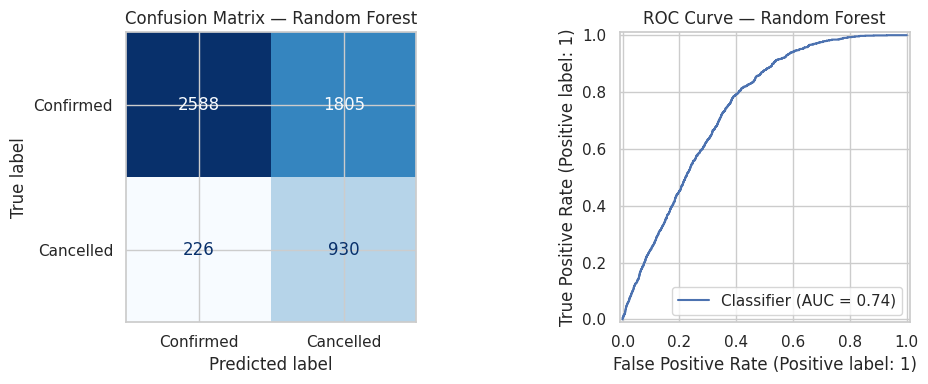

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions,
                                        display_labels=["Confirmed", "Cancelled"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix — {best_model_name}")
RocCurveDisplay.from_predictions(y_test, best_probabilities, ax=axes[1])
axes[1].set_title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.savefig("../visuals/model_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Feature importance (tree model)
The Random Forest feature importance is calculated after preprocessing, so one-hot encoded categories appear as separate features. Importance is a model-specific association measure, not a causal explanation.

,importance
categorical__is_weekend_checkin_False,0.288747
categorical__is_weekend_checkin_True,0.281392
numeric__booking_value,0.075979
categorical__booking_channel_Web,0.047788
numeric__cashback,0.039167
categorical__booking_channel_Mobile App,0.028179
numeric__star_rating,0.026008
categorical__room_type_Standard,0.023783
numeric__coupon_redeem,0.021535
categorical__booking_channel_Travel Agent,0.016415


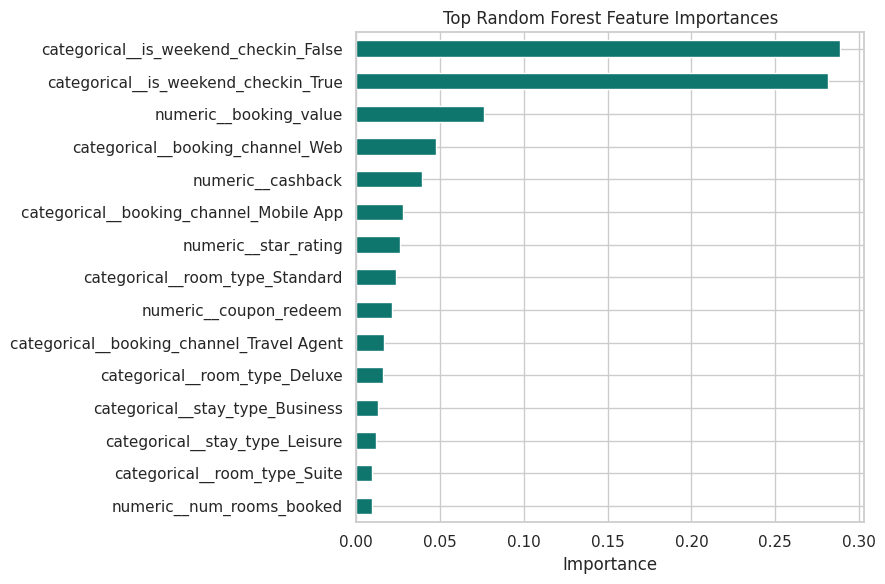

In [8]:
rf_pipeline = pipelines["Random Forest"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_preprocessor.get_feature_names_out()
importance = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
display(importance.head(15).to_frame("importance"))
ax = importance.head(15).sort_values().plot(kind="barh", figsize=(9, 6), color="#0F766E")
ax.set_title("Top Random Forest Feature Importances")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("../visuals/random_forest_feature_importance.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Save the selected baseline model and metrics
The model is saved with joblib. The saved object includes preprocessing and estimator steps. It should be loaded only with compatible versions of scikit-learn and its dependencies.

In [9]:
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump(best_pipeline, "../models/cancellation_prediction_pipeline.joblib")
results_df.to_csv("../visuals/model_comparison.csv", index=False)
print("Saved model: ../models/cancellation_prediction_pipeline.joblib")
print("Saved metrics: ../visuals/model_comparison.csv")

Saved model: ../models/cancellation_prediction_pipeline.joblib
Saved metrics: ../visuals/model_comparison.csv


## 8. Business interpretation and limitations
A cancellation-risk score could help a booking team prioritize reminder messages or review policies for selected segments. Before operational use, the business should choose a threshold based on the relative costs of false positives and missed cancellations, validate the model on a later time period, monitor drift, and confirm that every input is available at prediction time.

Limitations:
- The dataset is a single supplied extract; no external validation period is provided.
- Identifiers and ambiguous date fields are excluded.
- Failed bookings are outside this binary target.
- Some fields may have undocumented definitions or capture timing.
- Model performance is not evidence that an intervention will reduce cancellations.
- A random stratified split estimates performance on a similar sample; a chronological split would be preferable for deployment evaluation if sufficient time coverage and sample size are available.